# Supplementary Figure 10: sensitivity to uniform and random initialization

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb

OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Supplementary_Figure_10_outputs")
PCN_CAPACITY_GRID=(np.array([100],dtype=int) if RUN_MODE=="quick" else np.arange(20,101,5,dtype=int))
CONDITIONS=("transposition on","transposition off")
RANDOM_SEEDS=tuple(range(5))


In [2]:
rows=[]
for max_pcn in PCN_CAPACITY_GRID:
    configs={c.condition:c for c in standard_configurations(int(max_pcn))}
    for condition in CONDITIONS:
        r=evaluate_configuration(int(max_pcn),configs[condition],initial_state=uniform_initial_state(int(max_pcn)))
        r.update({"initialization":"uniform","seed":np.nan}); rows.append(r)
        for seed in RANDOM_SEEDS:
            init=random_initial_state(int(max_pcn),np.random.default_rng(seed))
            r=evaluate_configuration(int(max_pcn),configs[condition],initial_state=init)
            r.update({"initialization":"random","seed":seed}); rows.append(r)
results=pd.DataFrame(rows)

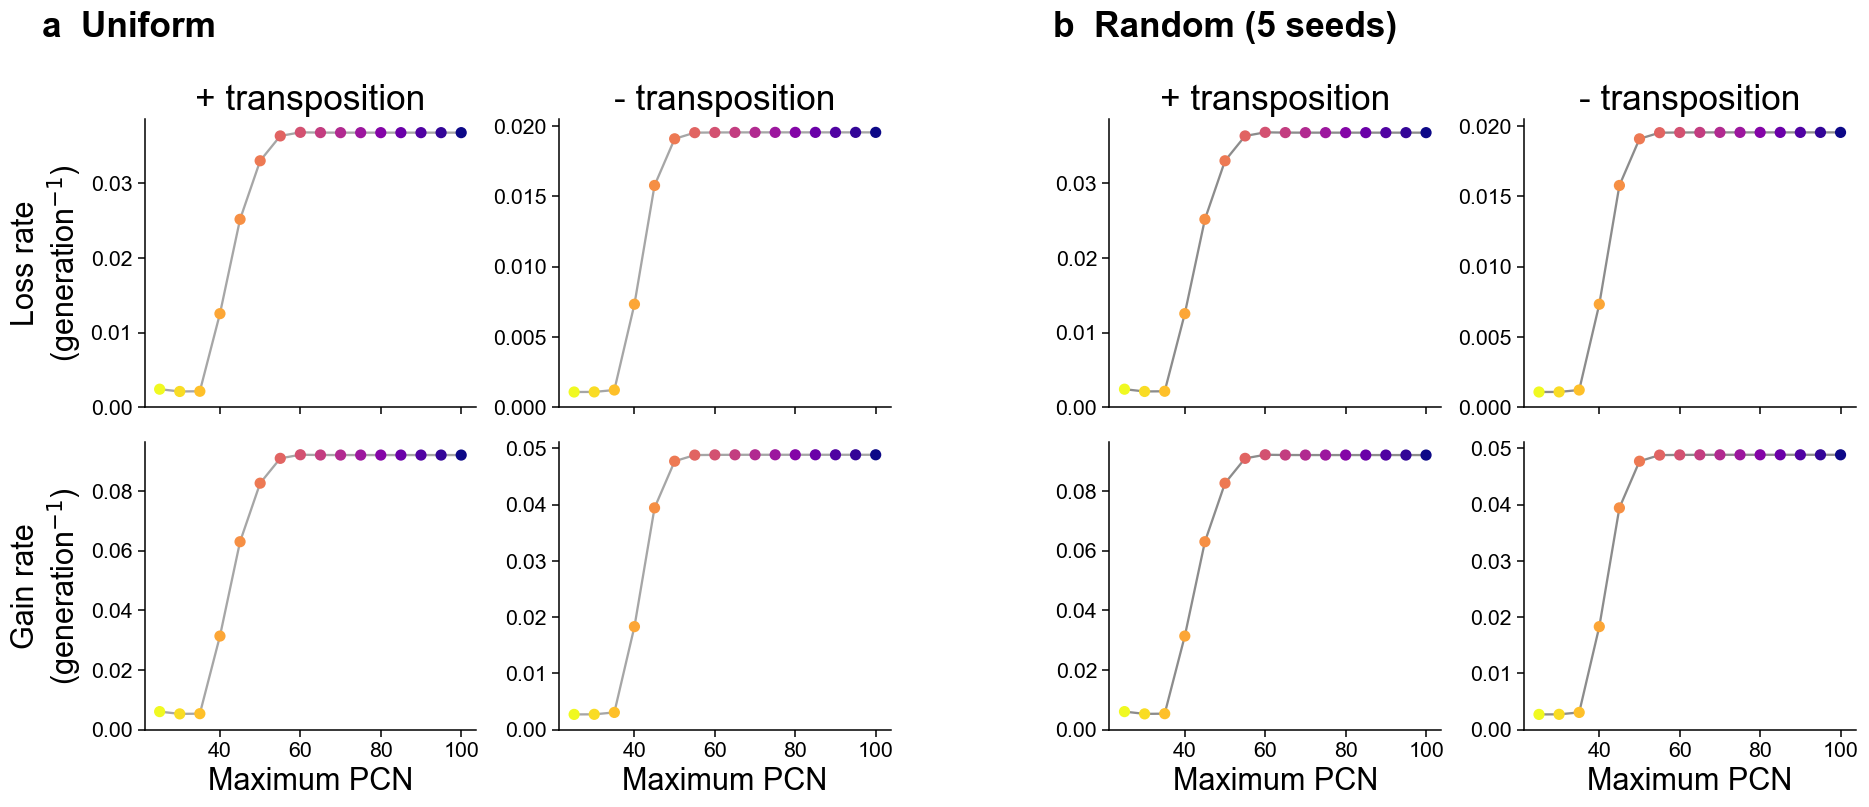

In [4]:
plt.rcParams.update(PLOT_STYLE)
LARGE_FONT_STYLE = {
    "font.size": 14, "axes.labelsize": 20, "axes.titlesize": 23,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 17,
    "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
}
plt.rcParams.update(LARGE_FONT_STYLE)
PANEL_FONT = 23
fig=plt.figure(figsize=(17.0,7.6))
gs=fig.add_gridspec(2,5,width_ratios=[1,1,0.16,1,1],left=0.075,right=0.99,
                    bottom=0.11,top=0.84,wspace=0.30,hspace=0.12)
axes=np.empty((2,4),dtype=object)
for col,gcol in enumerate((0,1,3,4)):
    axes[0,col]=fig.add_subplot(gs[0,gcol])
    axes[1,col]=fig.add_subplot(gs[1,gcol],sharex=axes[0,col])
for group,init_type in enumerate(("uniform","random")):
    for col_in_group,condition in enumerate(CONDITIONS):
        col=group*2+col_in_group
        for row,(metric,phase) in enumerate((("loss_rate","loss"),("gain_rate","gain"))):
            ax=axes[row,col]
            if init_type=="uniform":
                d=results[(results.initialization=="uniform")&(results.condition==condition)&results.response_valid].sort_values("maximum_PCN")
                ax.plot(d.maximum_PCN,d[metric],color="0.65",lw=1.5)
                ax.scatter(d.maximum_PCN,d[metric],c=d.maximum_PCN,cmap="plasma_r",s=40,zorder=3)
            else:
                d=results[(results.initialization=="random")&(results.condition==condition)&results.response_valid]
                s=d.groupby("maximum_PCN")[metric].agg(["mean","min","max"]).reset_index().sort_values("maximum_PCN")
                ax.fill_between(s.maximum_PCN,s["min"],s["max"],color="0.85",lw=0)
                ax.plot(s.maximum_PCN,s["mean"],color="0.55",lw=1.5)
                ax.scatter(s.maximum_PCN,s["mean"],c=s.maximum_PCN,cmap="plasma_r",s=40,zorder=3)
            ax.set_ylim(bottom=0)
            if row==1: ax.set_xlabel("Maximum PCN")
            else: ax.tick_params(axis="x",labelbottom=False)
            if col==0: ax.set_ylabel(f"{phase.capitalize()} rate\n(generation$^{{-1}}$)")
            if row==0: ax.set_title("+ transposition" if condition=="transposition on" else "- transposition")
fig.align_ylabels(axes[:,0])
for col,text in ((0,"a  Uniform"),(2,"b  Random (5 seeds)")):
    x0=axes[0,col].get_position().x0
    fig.text(x0-0.055 if col==0 else x0-0.03,0.95,text,fontweight="bold",va="center",ha="left",fontsize=PANEL_FONT)
save_figure(fig,"Supplementary_Figure_10_uniform_random_initialization",FIGURE_DIR); plt.show()

export_table(results,"Supplementary_Figure_10_source_data.csv",SOURCE_DIR)
meta=core_metadata("Supplementary Figure 10"); meta["random_seeds"]="0,1,2,3,4"
export_table(meta,"Supplementary_Figure_10_run_metadata.csv",SOURCE_DIR)
